In [1]:
import pandas as pd

In [29]:
path_meta = '../data/raw/metadata.csv'
df = pd.read_csv(path_meta)

In [6]:
df.head()

,building_id,site_id,building_id_kaggle,site_id_kaggle,primaryspaceusage,sub_primaryspaceusage,sqm,sqft,lat,lng,...,yearbuilt,date_opened,numberoffloors,occupants,energystarscore,eui,site_eui,source_eui,leed_level,rating
0,Panther_lodging_Dean,Panther,NaN,0.0,Lodging/residential,Residence Hall,508.8,5477.0,28.517689,-81.379039,...,1989.0,NaN,NaN,NaN,NaN,271,NaN,NaN,NaN,NaN
1,Panther_lodging_Shelia,Panther,NaN,0.0,Lodging/residential,Residence Hall,929.0,10000.0,28.517689,-81.379039,...,1992.0,NaN,NaN,NaN,NaN,62,NaN,NaN,NaN,NaN
2,Panther_lodging_Ricky,Panther,NaN,0.0,Lodging/residential,Residence Hall,483.1,5200.0,28.517689,-81.379039,...,2016.0,NaN,NaN,NaN,NaN,534,NaN,NaN,NaN,NaN
3,Panther_education_Rosalie,Panther,0.0,0.0,Education,Research,690.5,7432.0,28.517689,-81.379039,...,2008.0,NaN,NaN,NaN,NaN,276,NaN,NaN,NaN,NaN
4,Panther_education_Misty,Panther,1.0,0.0,Education,Research,252.7,2720.0,28.517689,-81.379039,...,2004.0,NaN,NaN,NaN,NaN,375,NaN,NaN,NaN,NaN


In [7]:
rows, cols = df.shape   

In [8]:
print(rows, cols)

1636 32


In [17]:
df["electricity"].value_counts(dropna=False)

electricity
Yes    1578
NaN      58
Name: count, dtype: int64

In [18]:
elec = df[df["electricity"] == "Yes"]

In [19]:
len(elec)

1578

In [21]:
elec["site_id"].value_counts(dropna=False)

site_id
Rat         305
Hog         152
Lamb        146
Fox         137
Bull        123
Cockatoo    117
Eagle       106
Panther     105
Bear         92
Gator        74
Robin        52
Peacock      45
Wolf         36
Bobcat       35
Swan         19
Moose        13
Shrew         9
Mouse         7
Crow          5
Name: count, dtype: int64

In [22]:
df[["site_id", "timezone"]]

,site_id,timezone
0,Panther,US/Eastern
1,Panther,US/Eastern
2,Panther,US/Eastern
3,Panther,US/Eastern
4,Panther,US/Eastern
...,...,...
1631,Mouse,Europe/London
1632,Mouse,Europe/London
1633,Mouse,Europe/London
1634,Mouse,Europe/London


In [23]:
df[["site_id","timezone"]].drop_duplicates()

,site_id,timezone
0,Panther,US/Eastern
136,Robin,Europe/London
188,Fox,US/Mountain
325,Rat,US/Eastern
630,Bear,US/Pacific
722,Lamb,Europe/London
869,Peacock,US/Eastern
916,Moose,US/Eastern
931,Gator,US/Eastern
1005,Bull,US/Central


In [27]:
Time_zone = df[["site_id","timezone"]].drop_duplicates()

In [28]:
Time_zone["timezone"].value_counts()

timezone
US/Eastern       8
Europe/London    4
US/Mountain      2
US/Pacific       2
US/Central       2
Europe/Dublin    1
Name: count, dtype: int64

In [33]:
path_elec = '../data/raw/electricity_cleaned.csv'
df_elec = pd.read_csv(path_elec , parse_dates=["timestamp"])

In [35]:
df_elec.shape

(17544, 1579)

In [37]:
df_elec.head()

,timestamp,Panther_parking_Lorriane,Panther_lodging_Cora,Panther_office_Hannah,Panther_lodging_Hattie,Panther_education_Teofila,Panther_education_Jerome,Panther_retail_Felix,Panther_parking_Asia,Panther_education_Misty,...,Cockatoo_public_Caleb,Cockatoo_education_Tyler,Cockatoo_public_Shad,Mouse_health_Buddy,Mouse_health_Modesto,Mouse_lodging_Vicente,Mouse_health_Justin,Mouse_health_Ileana,Mouse_health_Estela,Mouse_science_Micheal
0,2016-01-01 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,123.200,727.575,69.200,8.8224,370.0870,10.0,282.9965,26.0,135.0,168.2243
1,2016-01-01 01:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,126.475,731.200,66.275,17.6449,737.8260,30.0,574.9265,51.0,265.0,336.4486
2,2016-01-01 02:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,127.825,724.675,64.675,17.6449,729.9255,30.0,570.2780,50.0,272.0,336.4486
3,2016-01-01 03:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,130.475,737.375,65.875,17.6449,722.2620,20.0,561.1470,52.0,276.0,336.4486
4,2016-01-01 04:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,129.675,721.150,66.275,17.6449,719.1665,30.0,564.3695,50.0,280.0,336.4486


In [38]:
df_elec["timestamp"].min()

Timestamp('2016-01-01 00:00:00')

In [39]:
df_elec["timestamp"].max()

Timestamp('2017-12-31 23:00:00')

In [56]:
df_elec = df_elec.set_index("timestamp")
missing = df_elec.isna().mean()

KeyError: "None of ['timestamp'] are in the columns"

In [48]:
sorted_missing = missing.sort_values(ascending=False)

In [50]:
sorted_missing.head(10)

Eagle_assembly_Noel        1.000000
Hog_assembly_Arlie         1.000000
Hog_assembly_Marilynn      1.000000
Hog_assembly_Una           1.000000
Eagle_lodging_Garland      1.000000
Rat_public_Ulysses         1.000000
Hog_parking_Joan           0.999886
Gator_assembly_Elliot      0.998632
Bobcat_education_Barbra    0.993730
Hog_assembly_Annemarie     0.985522
dtype: float64

In [74]:
x = (missing > 0.05)
print(x)

Panther_parking_Lorriane     True
Panther_lodging_Cora         True
Panther_office_Hannah        True
Panther_lodging_Hattie       True
Panther_education_Teofila    True
                             ... 
Mouse_lodging_Vicente        True
Mouse_health_Justin          True
Mouse_health_Ileana          True
Mouse_health_Estela          True
Mouse_science_Micheal        True
Length: 1578, dtype: bool


In [57]:
missing.mean()

np.float64(0.08928675148545578)

In [58]:
missing.median()

np.float64(0.011200410396716827)

In [104]:
missing_2016 = df_elec.loc["2016"].isna().mean()
# missing_2016

In [105]:
missing_2017 = df_elec.loc["2017"].isna().mean()
# missing_2017

In [111]:
site = missing.index.str.split("_").str[0]
total = missing.groupby(site).size()
rows = {}
for t in [0.05, 0.10, 0.20, 0.50]:
    kept = missing[missing <= t]                      # keep buildings with missing <= t
    kept_site = kept.index.str.split("_").str[0]
    rows[t] = kept.groupby(kept_site).size().reindex(total.index, fill_value=0)
table_total = pd.DataFrame(rows)
table_total["total"] = total
# table_total

In [112]:
site = missing_2016.index.str.split("_").str[0]
total = missing_2016.groupby(site).size()
rows = {}
for t in [0.05, 0.10, 0.20, 0.50]:
    kept = missing_2016[missing_2016 <= t]                      # keep buildings with missing <= t
    kept_site = kept.index.str.split("_").str[0]
    rows[t] = kept.groupby(kept_site).size().reindex(total.index, fill_value=0)
table_2016 = pd.DataFrame(rows)
table_2016["total"] = total
# table_2016

In [113]:
totalsite = missing_2017.index.str.split("_").str[0]
total = missing_2017.groupby(site).size()
rows = {}
for t in [0.05, 0.10, 0.20, 0.50]:
    kept = missing_2017[missing_2017 <= t]                      # keep buildings with missing <= t
    kept_site = kept.index.str.split("_").str[0]
    rows[t] = kept.groupby(kept_site).size().reindex(total.index, fill_value=0)
table_2017 = pd.DataFrame(rows)
table_2017["total"] = total
# table_2017

In [114]:
compare = pd.concat(
    [table_total, table_2016, table_2017],
    axis=1,
    keys=["total", "2016", "2017"]
)
compare

total                      2016                      2017            \
          0.05  0.1  0.2  0.5 total 0.05  0.1  0.2  0.5 total 0.05  0.1  0.2   
Bear        78   80   85   92    92   78   78   81   86    92   89   91   91   
Bobcat       0   12   22   27    35   21   21   24   28    35    0    0   15   
Bull       109  117  119  123   123  114  115  120  122   123  115  117  122   
Cockatoo     0  104  109  114   117    0    0  108  113   117  108  110  112   
Crow         0    4    5    5     5    5    5    5    5     5    0    0    4   
Eagle       75   93   98  101   106   66   93   96  102   106   78   97  100   
Fox        128  131  134  135   137  129  132  133  136   137  131  133  134   
Gator       21   58   62   70    74   22   40   66   69    74   44   61   65   
Hog        136  137  140  143   152  139  140  140  140   152  140  140  141   
Lamb        83  124  132  144   146  127  137  140  143   146   85   85  133   
Moose        9    9    9   12    13   10   10   10   11    13   11   11   11   
Mouse        0    4    5    5     7    5    5    5    7     7    0    0    4   
Panther      0    0   93  105   105    0    0    0  103   105  101  105  105   
Peacock     36   36   36   36    45   36   36   36   36    45   36   36   43   
Rat        257  260  264  280   305  270  277  283  295   305  254  262  264   
Robin       51   51   51   51    52   51   51   52   52    52   51   51   51   
Shrew        0    0    0    9     9    9    9    9    9     9    0    0    0   
Swan         0    0    0    0    19    0    0    0    0    19   14   15   19   
Wolf        36   36   36   36    36   35   36   36   36    36   36   36   36   

                     
          0.5 total  
Bear       91    92  
Bobcat     26    35  
Bull      122   123  
Cockatoo  114   117  
Crow        5     5  
Eagle     102   106  
Fox       136   137  
Gator      66    74  
Hog       146   152  
Lamb      134   146  
Moose      11    13  
Mouse       5     7  
Panther   105   105  
Peacock    44    45  
Rat       271   305  
Robin      51    52  
Shrew       0     9  
Swan       19    19  
Wolf       36    36

In [122]:
for t in [0.05, 0.10, 0.20, 0.30, 0.40, 0.50, 0.35]:
    kept = missing[(missing_2016 <= t) & (missing_2017 <= t)]
    kept_site = kept.index.str.split("_").str[0]
    rows[t] = kept.groupby(kept_site).size().reindex(total.index, fill_value=0)
table = pd.DataFrame(rows)
table["total"] = total
table

,0.05,0.1,0.2,0.5,0.3,0.4,0.35,total
Bear,77,78,81,85,83,85,84,92
Bobcat,0,0,13,26,24,25,25,35
Bull,107,109,119,121,119,119,119,123
Cockatoo,0,0,107,113,111,113,111,117
Crow,0,0,4,5,5,5,5,5
Eagle,63,89,94,100,97,100,97,106
Fox,125,130,131,135,134,134,134,137
Gator,18,36,61,64,64,64,64,74
Hog,135,136,137,140,140,140,140,152
Lamb,79,83,130,133,131,133,132,146


<Axes: >

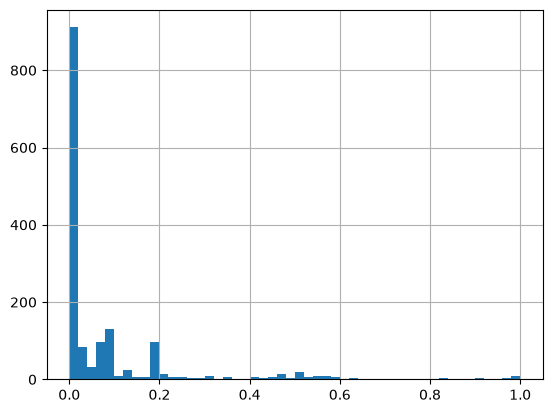

In [123]:
missing.hist(bins=50)

In [124]:
df_elec["<one Panther building>"].first_valid_index()

KeyError: '<one Panther building>'